#### What am I Up To


- Updating paper for CVPR (Due Nov 11)
- Added Distilation to replay embeddings 
- Update Thesis


### Remind 

#### Results so far (11 tasks)

| Method | Memory per example | Last ↑ | Transfer ↑ |
|---|---|---|---|
| ZSCL only (no replay) | – | 83.79 |69.39 |
| Image replay (our paper) | 602 KB | 86.17 |  69.18 |
| Final-embedding replay | 1 KB | 84.79 |  68.81 |
| **Compressed-feature replay** | ~25 KB | 86.36 |  69.07 |
| + distill from original CLIP | ~25 KB | 86.05 | 68.28 |

- Compressed features match image replay at ~1/24 the memory.
- Distilling from the original CLIP does not help.
- The model barely forgets (< 1 pt); the limit is how well it learns each new task.

#### Forgetting: is there anything left for distillation to recover?

Forgetting for task *k* is **peak − final**: the best accuracy task *k* ever reached, minus its accuracy after the last task (Chaudhry et al.). It is averaged over the 10 old tasks; SUN397 is the last task, so it can't be forgotten. **Last if zero forgetting** is the mean of each task's peak, i.e. the most Last could reach if an anti-forgetting term worked perfectly.

| Run | Mean forgetting (peak − final) ↓ | Worst task | Last | Last if zero forgetting | Max gain |
|---|---|---|---|---|---|
| ZSCL only (no replay) | 3.66 | Aircraft 13.6 | 83.79 | 87.12 | +3.33 |
| Pixel replay, seed 1 | 1.35 | CIFAR100 3.5 | 86.34 | 87.56 | +1.22 |
| Pixel replay, seed 2 | 1.36 | EuroSAT 3.7 | 86.34 | 87.58 | +1.23 |
| REMIND + RD current (R0) | 1.05 | EuroSAT 1.9 | 86.04 | 86.99 | +0.95 |
| **REMIND, no RD (R1)** | 0.89 | CIFAR100 2.2 | 86.36 | 87.18 | +0.81 |

1. **Replay already removes most forgetting.** It drops from 3.7 points to 0.9, about 75% gone. Without replay, Aircraft loses 13.6 points; with replay, it ends up higher than its diag (backward transfer).
2. **That sets a hard ceiling on what distillation can do.** At best, an anti-forgetting term restores every old task to its peak. For R1 that means Last can rise from 86.36 to about 87.2 (+0.8), and only if forgetting goes to exactly zero.
3. **The measurement is reliable.** The two pixel seeds agree to 0.01 (1.35 vs. 1.36), so a sub-1-point forgetting figure is a real result, not noise.
4. **Distillation made forgetting slightly worse.** R0, which adds CLIP-teacher RD, forgets 1.05 vs. 0.89 for R1. That fits the hypothesis: a zero-shot teacher pulls old tasks back toward zero-shot behaviour instead of preserving what was learned.
5. **What's left is concentrated in a few tasks.** CIFAR100, EuroSAT and Food (about 1.3–2.2 each) account for most of it. Most other tasks are under 1 point. Any future fix should target those tasks, not the overall average.


#### Per-task forgetting (no replay vs. REMIND)

F = peak − final. R1 = REMIND block 2, m=128, no RD; R0 = same + RD on current images.

| Task | ZSCL-only diag | ZSCL-only final | ZSCL-only F | R1 diag | R1 peak | R1 final | R1 F | R0 F |
|---|---|---|---|---|---|---|---|---|
| Aircraft | 53.20 | 39.57 | 13.62 | 52.90 | 54.28 | 53.80 | **0.48** | 1.05 |
| Caltech101 | 95.45 | 91.88 | 3.57 | 93.43 | 93.43 | 92.57 | **0.86** | 1.73 |
| CIFAR100 | 85.86 | 79.94 | 5.92 | 85.21 | 85.21 | 83.05 | **2.16** | 1.41 |
| DTD | 78.46 | 74.95 | 3.51 | 78.40 | 78.40 | 77.34 | **1.06** | 0.53 |
| EuroSAT | 98.26 | 95.94 | 2.31 | 97.59 | 97.59 | 96.28 | **1.31** | 1.87 |
| Flowers | 97.33 | 92.18 | 5.16 | 97.20 | 97.20 | 97.15 | **0.05** | 0.21 |
| Food | 91.74 | 91.36 | 0.38 | 91.44 | 91.44 | 90.13 | **1.31** | 1.27 |
| MNIST | 99.11 | 98.82 | 0.29 | 98.70 | 98.70 | 98.46 | **0.24** | 0.53 |
| OxfordPet | 95.31 | 95.09 | 0.22 | 95.26 | 95.26 | 94.74 | **0.52** | 0.35 |
| StanfordCars | 84.79 | 83.14 | 1.65 | 86.83 | 86.83 | 85.90 | **0.93** | 1.50 |

> **Takeaway:** Replay leaves under 1 point of forgetting, so Last is limited by how well each task is learned (diag), not by forgetting. Distillation has nothing left to recover.


#### Reference: Image-Anchored Distillation (IAD) on the REMIND buffer

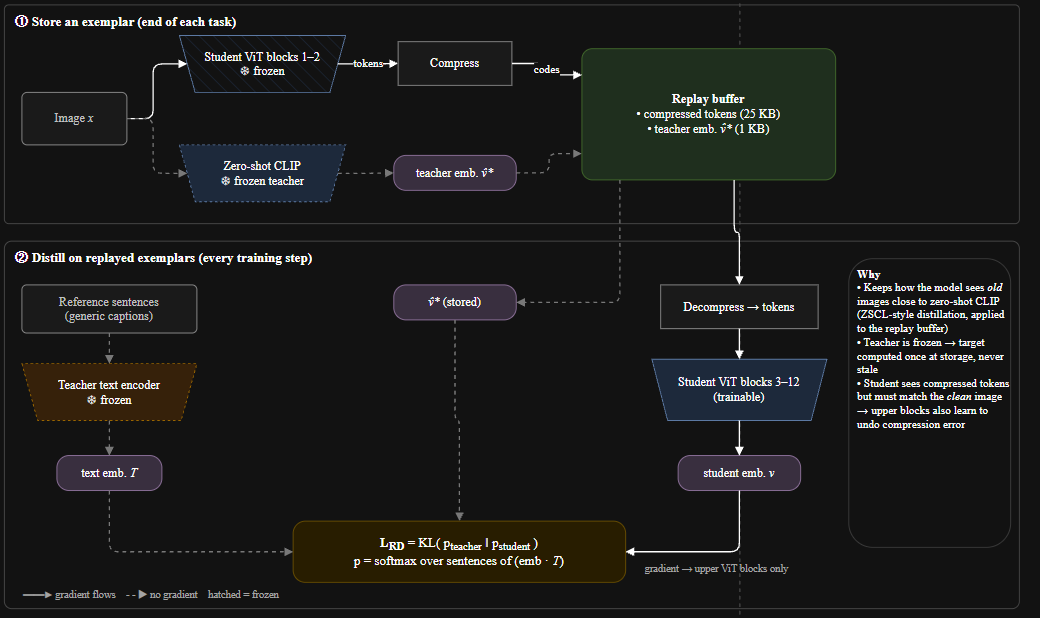
